In [1]:
import os
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy import signal
from scipy.stats import kurtosis
from scipy.optimize import linear_sum_assignment

from sklearn.decomposition import FastICA, PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    SpectralClustering
)
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

from sklearn.datasets import make_moons

# Random seed
SEED = 0
np.random.seed(SEED)

# Google Colab working directory
ROOT = "/content"

# Create result folders
FIG = os.path.join(ROOT, "results", "figures")
TAB = os.path.join(ROOT, "results", "tables")

os.makedirs(FIG, exist_ok=True)
os.makedirs(TAB, exist_ok=True)

print("Initialization successful!")
print("Figures folder:", FIG)
print("Tables folder:", TAB)

Initialization successful!
Figures folder: /content/results/figures
Tables folder: /content/results/tables


Source matrix shape: (2000, 3)
Mixed signal matrix shape: (2000, 3)
Mixing matrix condition number: 16.741039595141537


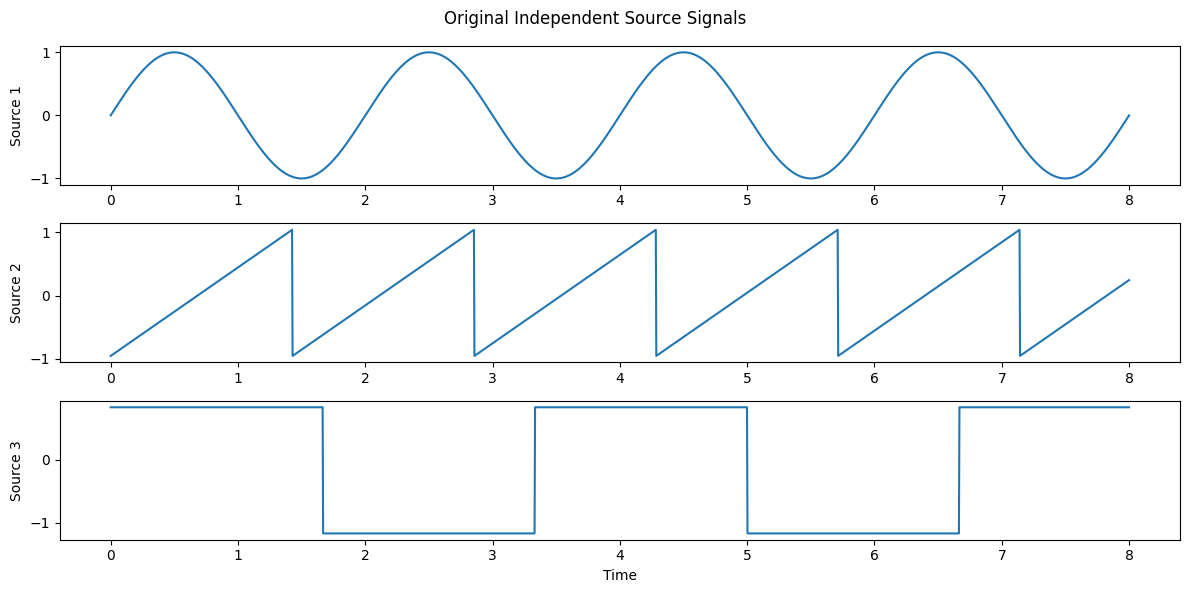

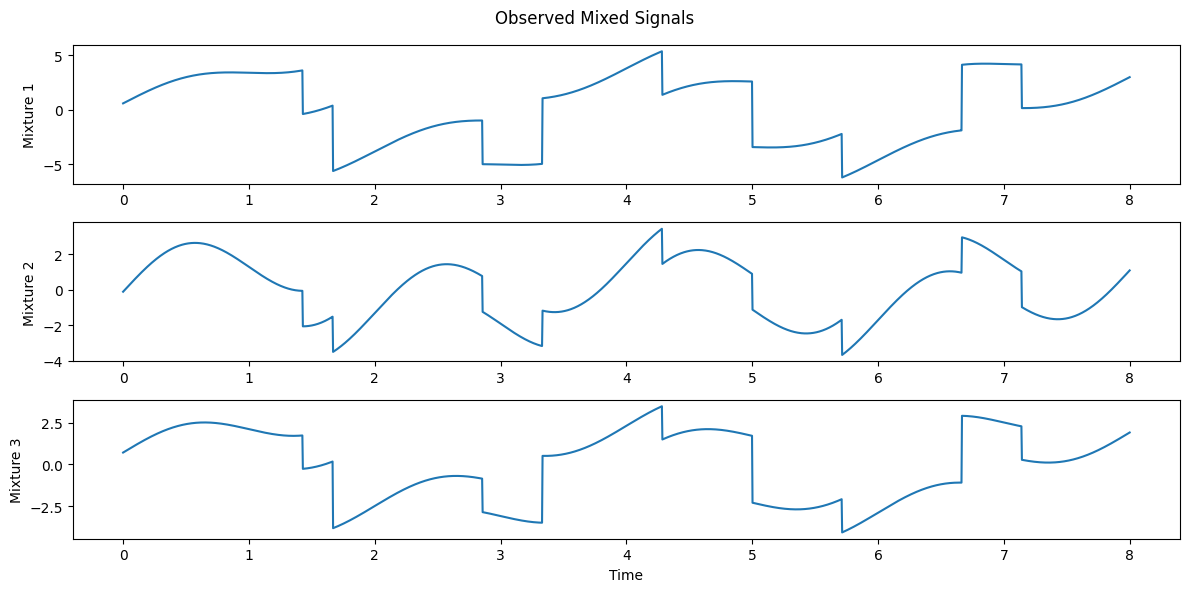

In [2]:
# Generate three independent source signals
from scipy.signal import sawtooth, square

n_samples = 2000
t = np.linspace(0, 8, n_samples)

s1 = np.sin(2 * np.pi * 0.5 * t)
s2 = sawtooth(2 * np.pi * 0.7 * t)
s3 = square(2 * np.pi * 0.3 * t)

# Combine sources into a matrix
S = np.c_[s1, s2, s3]

# Center the source signals
S = S - np.mean(S, axis=0)

# Mixing matrix
A = np.array([
    [1.0, 2.0, 3.0],
    [2.0, 1.0, 1.0],
    [1.0, 1.0, 2.0]
])

# Generate observed mixed signals
X = S @ A.T

print("Source matrix shape:", S.shape)
print("Mixed signal matrix shape:", X.shape)
print("Mixing matrix condition number:", np.linalg.cond(A))

# Plot original sources
plt.figure(figsize=(12, 6))
for i in range(3):
    plt.subplot(3, 1, i + 1)
    plt.plot(t, S[:, i])
    plt.ylabel(f"Source {i+1}")
plt.xlabel("Time")
plt.suptitle("Original Independent Source Signals")
plt.tight_layout()
plt.show()

# Plot observed mixtures
plt.figure(figsize=(12, 6))
for i in range(3):
    plt.subplot(3, 1, i + 1)
    plt.plot(t, X[:, i])
    plt.ylabel(f"Mixture {i+1}")
plt.xlabel("Time")
plt.suptitle("Observed Mixed Signals")
plt.tight_layout()
plt.show()

Covariance before whitening:
[[10.17919228  4.28122443  6.71659673]
 [ 4.28122443  3.16433665  3.06609873]
 [ 6.71659673  3.06609873  4.51991594]]

Covariance after whitening:
[[ 1.00000000e+00  4.94074238e-16 -8.74601931e-15]
 [ 4.94074238e-16  1.00000000e+00 -1.18009099e-15]
 [-8.74601931e-15 -1.18009099e-15  1.00000000e+00]]


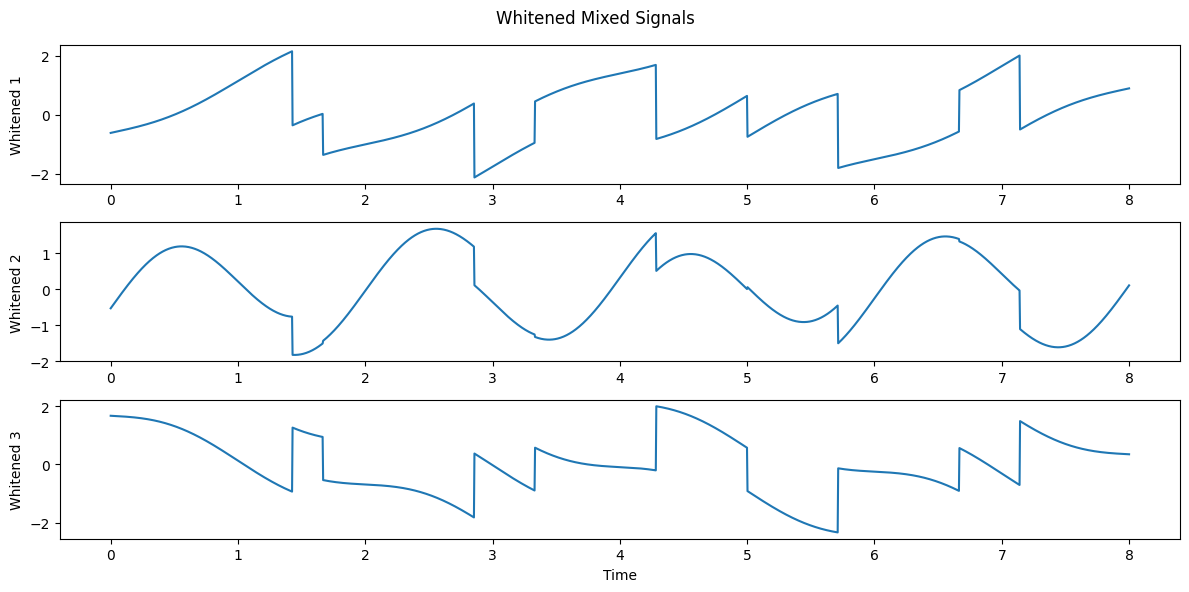

In [3]:
# Center the mixed signals
X_centered = X - np.mean(X, axis=0)

# Calculate covariance matrix
cov_X = np.cov(X_centered, rowvar=False)

# Eigenvalue decomposition
eigenvalues, eigenvectors = np.linalg.eigh(cov_X)

# Sort eigenvalues in descending order
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Whitening transformation
D_inv_sqrt = np.diag(1.0 / np.sqrt(eigenvalues))
W_white = eigenvectors @ D_inv_sqrt @ eigenvectors.T

X_white = X_centered @ W_white

# Check covariance after whitening
cov_white = np.cov(X_white, rowvar=False)

print("Covariance before whitening:")
print(cov_X)

print("\nCovariance after whitening:")
print(cov_white)

# Plot whitened signals
plt.figure(figsize=(12, 6))
for i in range(3):
    plt.subplot(3, 1, i + 1)
    plt.plot(t, X_white[:, i])
    plt.ylabel(f"Whitened {i+1}")
plt.xlabel("Time")
plt.suptitle("Whitened Mixed Signals")
plt.tight_layout()
plt.show()

ICA converged: 6 iterations
Recovered source matrix shape: (2000, 3)


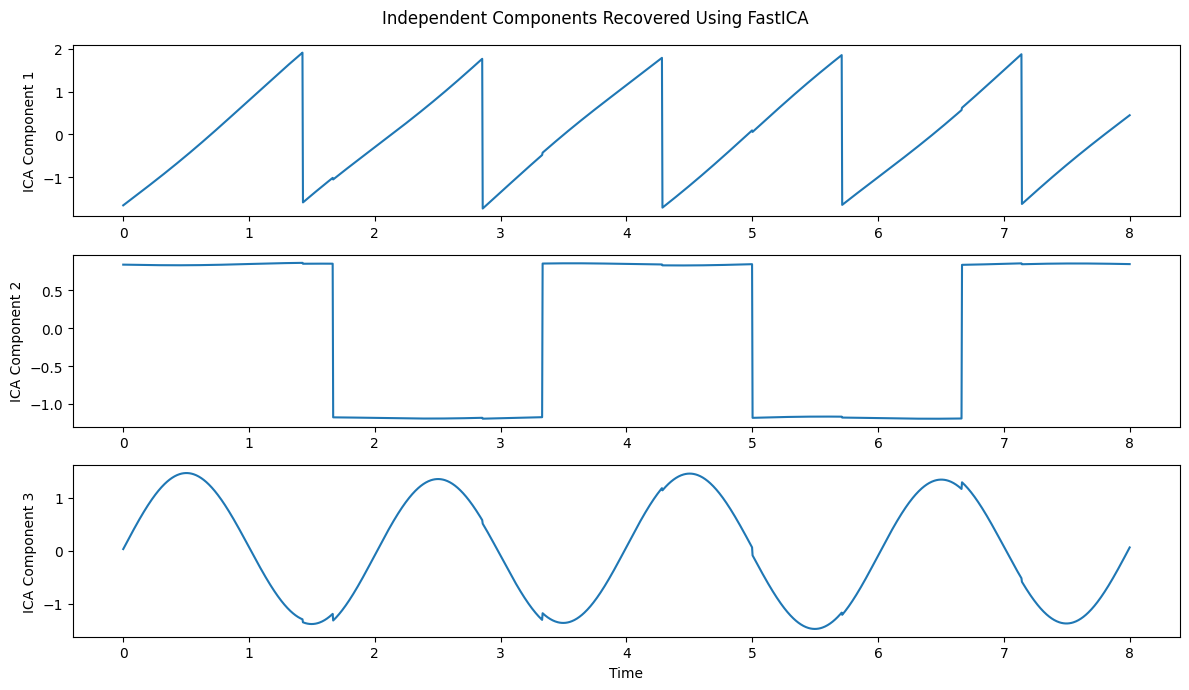

In [4]:
# Apply FastICA
ica = FastICA(
    n_components=3,
    random_state=SEED,
    max_iter=2000,
    tol=0.0001
)

S_ica = ica.fit_transform(X)

print("ICA converged:", ica.n_iter_, "iterations")
print("Recovered source matrix shape:", S_ica.shape)

# Plot recovered independent components
plt.figure(figsize=(12, 7))

for i in range(3):
    plt.subplot(3, 1, i + 1)
    plt.plot(t, S_ica[:, i])
    plt.ylabel(f"ICA Component {i+1}")

plt.xlabel("Time")
plt.suptitle("Independent Components Recovered Using FastICA")
plt.tight_layout()
plt.savefig(os.path.join(FIG, "ica_recovered_sources.png"), dpi=300)
plt.show()

PCA explained variance ratio:
[0.93410481 0.06404696 0.00184823]


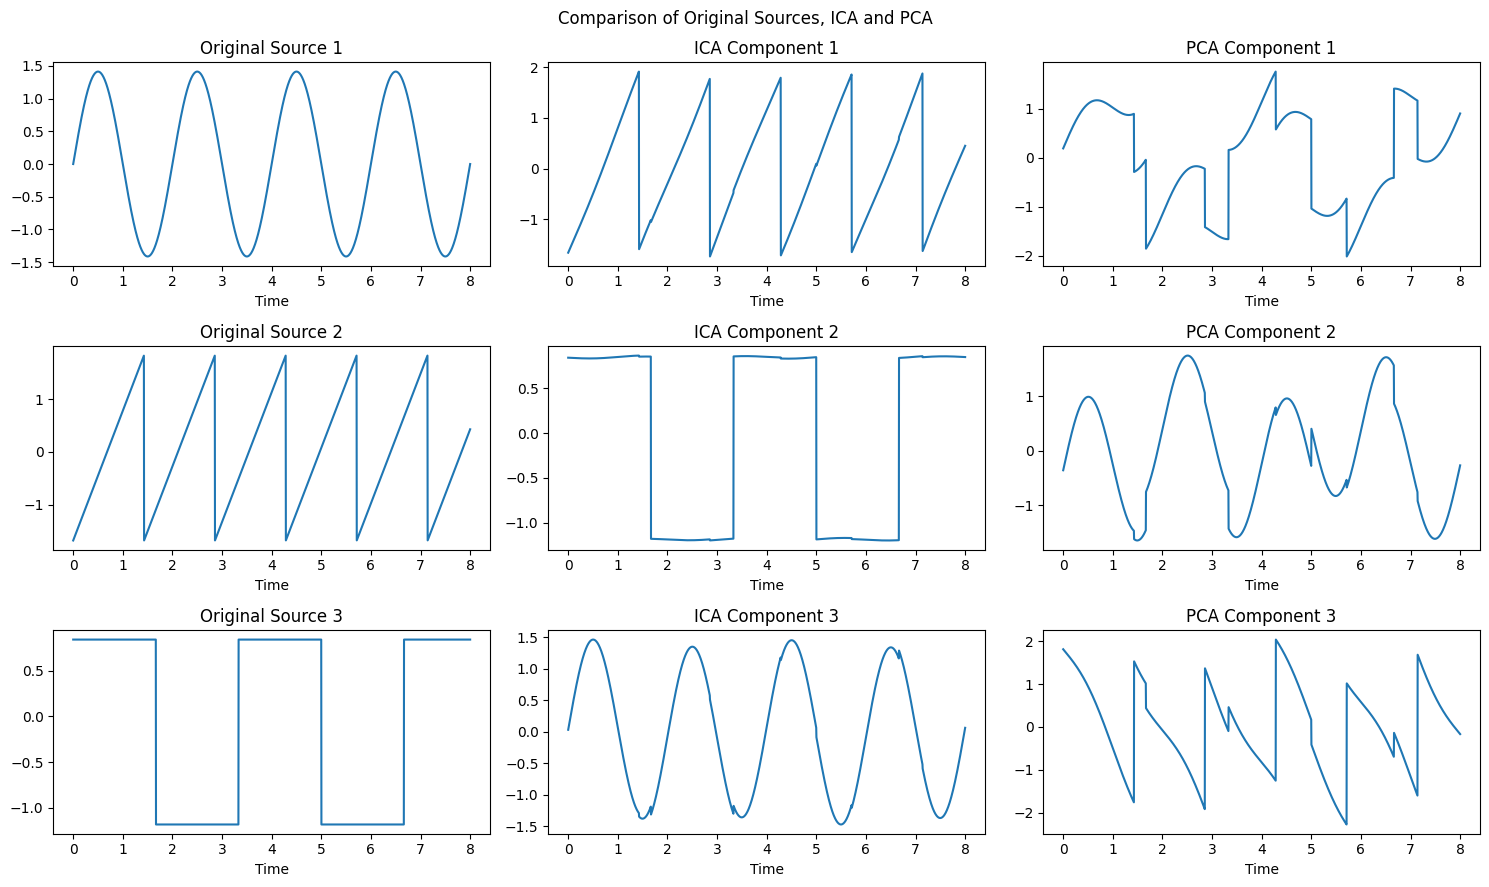

In [5]:
# Apply PCA
pca = PCA(n_components=3)
S_pca = pca.fit_transform(X)

print("PCA explained variance ratio:")
print(pca.explained_variance_ratio_)

# Normalize signals for visual comparison
def normalize_signals(data):
    return (data - np.mean(data, axis=0)) / (
        np.std(data, axis=0) + 1e-10
    )

S_original_norm = normalize_signals(S)
S_ica_norm = normalize_signals(S_ica)
S_pca_norm = normalize_signals(S_pca)

# Plot original, ICA and PCA signals
fig, axes = plt.subplots(3, 3, figsize=(15, 9))

for i in range(3):
    axes[i, 0].plot(t, S_original_norm[:, i])
    axes[i, 0].set_title(f"Original Source {i+1}")

    axes[i, 1].plot(t, S_ica_norm[:, i])
    axes[i, 1].set_title(f"ICA Component {i+1}")

    axes[i, 2].plot(t, S_pca_norm[:, i])
    axes[i, 2].set_title(f"PCA Component {i+1}")

for ax in axes.flat:
    ax.set_xlabel("Time")

plt.suptitle("Comparison of Original Sources, ICA and PCA")
plt.tight_layout()
plt.savefig(os.path.join(FIG, "ica_vs_pca.png"), dpi=300)
plt.show()

Absolute correlation matrix:
[[0.704 0.053 0.708]
 [0.635 0.372 0.677]
 [0.314 0.93  0.19 ]]

Matched correlations:
[0.704 0.677 0.93 ]
Mean matched correlation: 0.7704373082556873


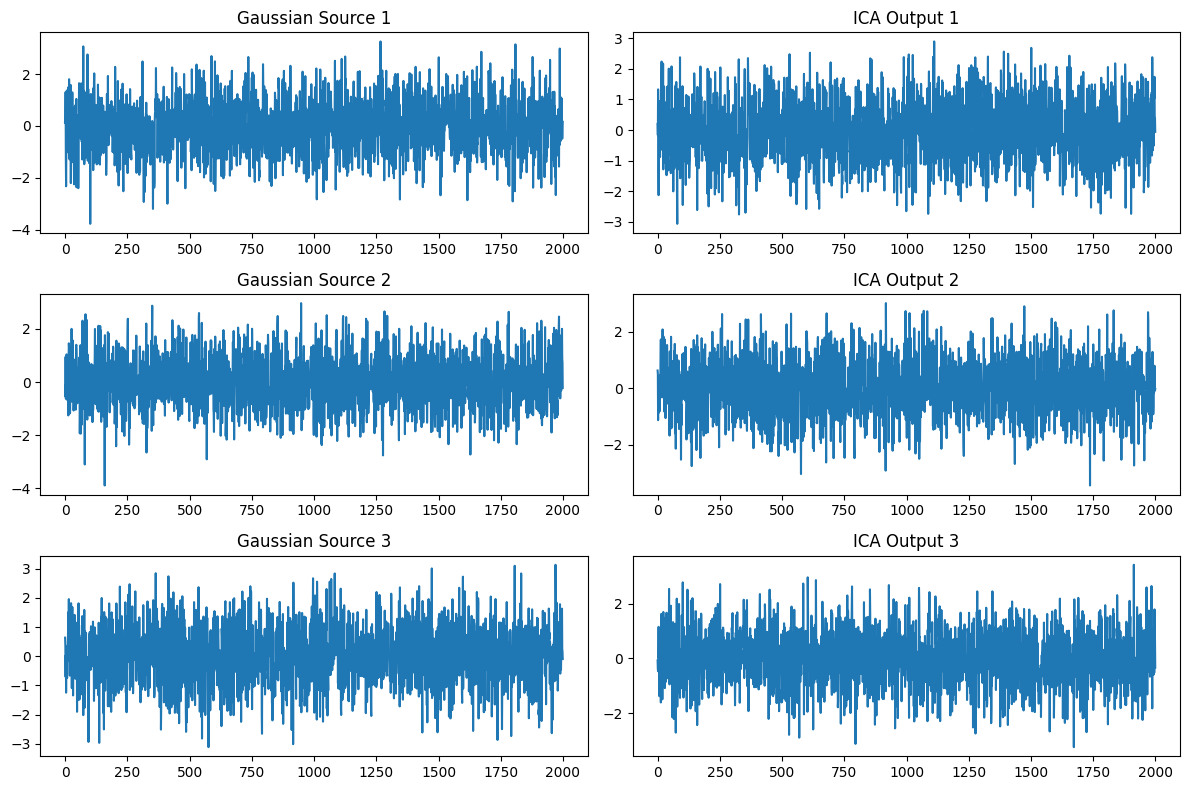

In [6]:
# Generate independent Gaussian sources
rng = np.random.default_rng(SEED)

S_gaussian = rng.normal(size=(n_samples, 3))

# Mix Gaussian sources using the same mixing matrix
X_gaussian = S_gaussian @ A.T

# Apply FastICA
ica_gaussian = FastICA(
    n_components=3,
    random_state=SEED,
    max_iter=2000,
    tol=0.0001
)

S_gaussian_ica = ica_gaussian.fit_transform(X_gaussian)

# Calculate absolute correlation between recovered and original sources
correlation_matrix = np.abs(
    np.corrcoef(S_gaussian.T, S_gaussian_ica.T)[:3, 3:]
)

print("Absolute correlation matrix:")
print(np.round(correlation_matrix, 3))

# Find best source matching
from scipy.optimize import linear_sum_assignment

rows, cols = linear_sum_assignment(-correlation_matrix)

matched_correlations = correlation_matrix[rows, cols]

print("\nMatched correlations:")
print(np.round(matched_correlations, 3))
print("Mean matched correlation:", np.mean(matched_correlations))

# Plot Gaussian sources and ICA outputs
fig, axes = plt.subplots(3, 2, figsize=(12, 8))

for i in range(3):
    axes[i, 0].plot(S_gaussian[:, i])
    axes[i, 0].set_title(f"Gaussian Source {i+1}")

    axes[i, 1].plot(S_gaussian_ica[:, i])
    axes[i, 1].set_title(f"ICA Output {i+1}")

plt.tight_layout()
plt.savefig(os.path.join(FIG, "gaussian_ica_test.png"), dpi=300)
plt.show()

Dataset shape: (4000, 4)
Labels shape: (4000,)
Classes: ['BPSK', 'QPSK', '8PSK', '16QAM']


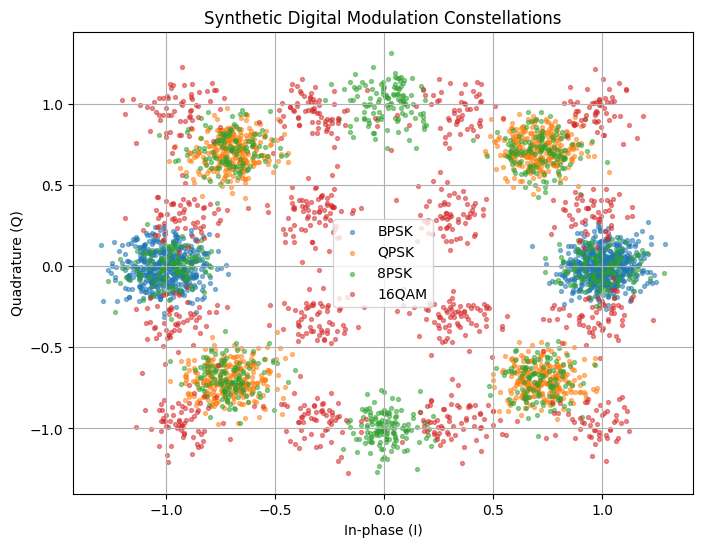

In [7]:
# Generate synthetic modulation signals
rng = np.random.default_rng(SEED)

n_per_class = 1000

def generate_modulation(modulation, n):
    if modulation == "BPSK":
        symbols = rng.choice([-1, 1], n) + 0j

    elif modulation == "QPSK":
        phases = rng.integers(0, 4, n) * np.pi / 2 + np.pi / 4
        symbols = np.exp(1j * phases)

    elif modulation == "8PSK":
        phases = rng.integers(0, 8, n) * 2 * np.pi / 8
        symbols = np.exp(1j * phases)

    elif modulation == "16QAM":
        levels = np.array([-3, -1, 1, 3])
        real = rng.choice(levels, n)
        imag = rng.choice(levels, n)
        symbols = (real + 1j * imag) / np.sqrt(10)

    # Add complex Gaussian noise
    noise = 0.1 * (
        rng.normal(size=n) + 1j * rng.normal(size=n)
    )

    return symbols + noise


modulations = ["BPSK", "QPSK", "8PSK", "16QAM"]

signals = []
labels = []

for class_id, modulation in enumerate(modulations):
    samples = generate_modulation(modulation, n_per_class)
    signals.append(samples)
    labels.extend([class_id] * n_per_class)

signals = np.concatenate(signals)
labels = np.array(labels)

# Extract basic I/Q features
X_mod = np.column_stack([
    signals.real,
    signals.imag,
    np.abs(signals),
    np.angle(signals)
])

print("Dataset shape:", X_mod.shape)
print("Labels shape:", labels.shape)
print("Classes:", modulations)

# Plot constellation diagram
plt.figure(figsize=(8, 6))

for class_id, modulation in enumerate(modulations):
    mask = labels == class_id
    plt.scatter(
        signals.real[mask],
        signals.imag[mask],
        s=8,
        alpha=0.5,
        label=modulation
    )

plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("Synthetic Digital Modulation Constellations")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(FIG, "modulation_constellations.png"), dpi=300)
plt.show()

In [8]:
# Calculate statistical features from complex signals
def extract_features(z):
    amplitude = np.abs(z)
    phase = np.angle(z)

    # Second- and fourth-order moments
    C20 = np.mean(z**2)
    C21 = np.mean(np.abs(z)**2)
    C40 = np.mean(z**4) - 3 * C20**2
    C42 = (
        np.mean(np.abs(z)**4)
        - abs(C20)**2
        - 2 * C21**2
    )

    return [
        np.std(amplitude),
        np.mean(amplitude**2),
        np.std(amplitude**2),
        kurtosis(amplitude),
        np.mean((amplitude - np.mean(amplitude))**3),
        abs(C20),
        abs(C40),
        abs(C42),
        abs(C40) / (C21**2 + 1e-10),
        abs(C42) / (C21**2 + 1e-10),
        np.std(phase),
        np.mean(np.abs(phase))
    ]


# Extract features for each signal sample
X_features = np.array([
    extract_features(np.array([sample]))
    for sample in signals
])

print("Extracted feature matrix shape:", X_features.shape)
print("\nFirst five feature rows:")
print(np.round(X_features[:5], 4))

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_features)

print("\nStandardized feature matrix shape:", X_scaled.shape)

Extracted feature matrix shape: (4000, 12)

First five feature rows:
[[0.     1.2915 0.        nan 0.     1.2915 3.3361 3.3361 2.     2.
  0.     0.0401]
 [0.     1.0054 0.        nan 0.     1.0054 2.0217 2.0217 2.     2.
  0.     0.0704]
 [0.     0.8508 0.        nan 0.     0.8508 1.4477 1.4477 2.     2.
  0.     0.0559]
 [0.     0.9764 0.        nan 0.     0.9764 1.9069 1.9069 2.     2.
  0.     3.0727]
 [0.     0.9579 0.        nan 0.     0.9579 1.8353 1.8353 2.     2.
  0.     3.1095]]

Standardized feature matrix shape: (4000, 12)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


In [10]:
# Extract features from groups of complex signal samples

def extract_features(z):
    amplitude = np.abs(z)
    phase = np.angle(z)

    C20 = np.mean(z**2)
    C21 = np.mean(np.abs(z)**2)
    C40 = np.mean(z**4) - 3 * C20**2
    C42 = (
        np.mean(np.abs(z)**4)
        - abs(C20)**2
        - 2 * C21**2
    )

    return [
        np.std(amplitude),
        np.mean(amplitude**2),
        np.std(amplitude**2),
        kurtosis(amplitude),
        np.mean((amplitude - np.mean(amplitude))**3),
        abs(C20),
        abs(C40),
        abs(C42),
        abs(C40) / (C21**2 + 1e-10),
        abs(C42) / (C21**2 + 1e-10),
        np.std(phase),
        np.mean(np.abs(phase))
    ]


# Divide each modulation class into groups
group_size = 100
X_features = []
y_features = []

for class_id in range(len(modulations)):
    class_signals = signals[labels == class_id]

    for start in range(0, len(class_signals), group_size):
        group = class_signals[start:start + group_size]

        if len(group) == group_size:
            X_features.append(extract_features(group))
            y_features.append(class_id)

X_features = np.array(X_features, dtype=float)
y_features = np.array(y_features)

# Replace any remaining invalid values
X_features = np.nan_to_num(
    X_features,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_features)

print("Feature matrix shape:", X_features.shape)
print("Labels shape:", y_features.shape)
print("NaN values:", np.isnan(X_scaled).sum())
print("Feature extraction completed!")

Feature matrix shape: (40, 12)
Labels shape: (40,)
NaN values: 0
Feature extraction completed!


Explained variance ratio:
[5.530e-01 2.156e-01 9.050e-02 8.040e-02 3.050e-02 2.420e-02 4.400e-03
 1.100e-03 2.000e-04 1.000e-04 0.000e+00 0.000e+00]

Cumulative explained variance:
[0.553  0.7686 0.8591 0.9395 0.97   0.9942 0.9986 0.9997 0.9999 1.
 1.     1.    ]

Components required for 90% variance: 4
Components required for 95% variance: 5


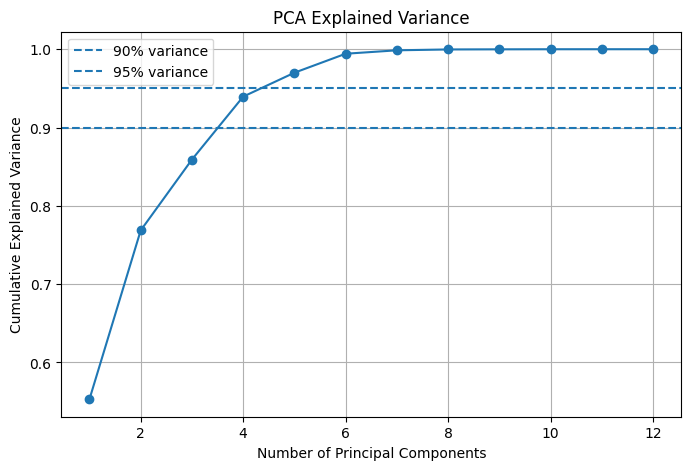

In [11]:
# Fit PCA on standardized features
pca_full = PCA()
X_pca = pca_full.fit_transform(X_scaled)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

print("Explained variance ratio:")
print(np.round(pca_full.explained_variance_ratio_, 4))

print("\nCumulative explained variance:")
print(np.round(cumulative_variance, 4))

# Find components required for 90% and 95% variance
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("\nComponents required for 90% variance:", n_90)
print("Components required for 95% variance:", n_95)

# Plot cumulative explained variance
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(0.90, linestyle="--", label="90% variance")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid(True)
plt.legend()
plt.savefig(os.path.join(FIG, "pca_explained_variance.png"), dpi=300)
plt.show()

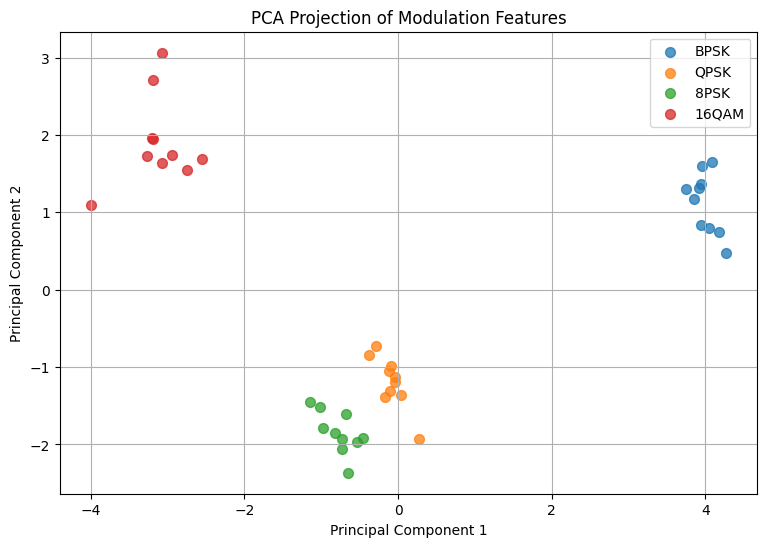

In [12]:
# Plot PCA projection using first two components
plt.figure(figsize=(9, 6))

for class_id, modulation in enumerate(modulations):
    mask = y_features == class_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=modulation,
        s=50,
        alpha=0.75
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection of Modulation Features")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(FIG, "pca_2d_projection.png"),
    dpi=300
)
plt.show()

Components: 2, Reconstruction MSE: 0.231436
Components: 4, Reconstruction MSE: 0.060549
Components: 8, Reconstruction MSE: 0.000294
Components: 12, Reconstruction MSE: 0.000000


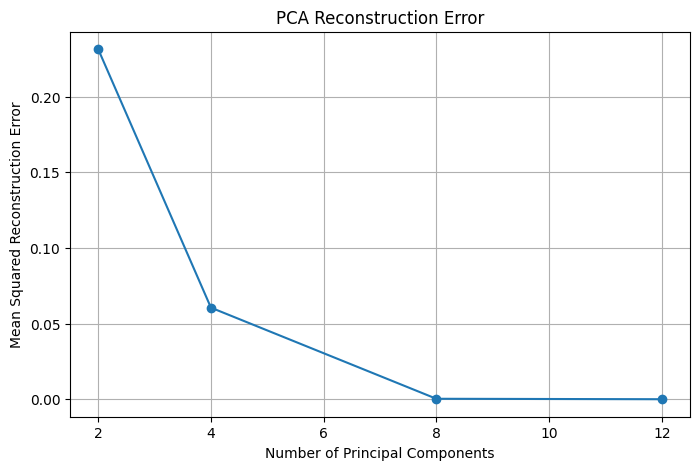

In [13]:
# PCA reconstruction error for different component counts
component_counts = [2, 4, 8, 12]
reconstruction_errors = []

for q in component_counts:
    pca_temp = PCA(n_components=q)
    reduced = pca_temp.fit_transform(X_scaled)
    reconstructed = pca_temp.inverse_transform(reduced)

    mse = np.mean((X_scaled - reconstructed) ** 2)
    reconstruction_errors.append(mse)

    print(f"Components: {q}, Reconstruction MSE: {mse:.6f}")

# Plot reconstruction error
plt.figure(figsize=(8, 5))
plt.plot(
    component_counts,
    reconstruction_errors,
    marker="o"
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Mean Squared Reconstruction Error")
plt.title("PCA Reconstruction Error")
plt.grid(True)

plt.savefig(
    os.path.join(FIG, "pca_reconstruction_error.png"),
    dpi=300
)
plt.show()

In [14]:
# Apply K-Means clustering
kmeans = KMeans(
    n_clusters=4,
    random_state=SEED,
    n_init=20
)

kmeans_labels = kmeans.fit_predict(X_scaled)

# Evaluate clustering
sil_score = silhouette_score(X_scaled, kmeans_labels)
ari = adjusted_rand_score(y_features, kmeans_labels)
nmi = normalized_mutual_info_score(y_features, kmeans_labels)

print("K-Means Clustering Results")
print("--------------------------")
print("Inertia:", round(kmeans.inertia_, 4))
print("Silhouette Score:", round(sil_score, 4))
print("Adjusted Rand Index:", round(ari, 4))
print("Normalized Mutual Information:", round(nmi, 4))

K-Means Clustering Results
--------------------------
Inertia: 92.5091
Silhouette Score: 0.5642
Adjusted Rand Index: 0.6656
Normalized Mutual Information: 0.8294


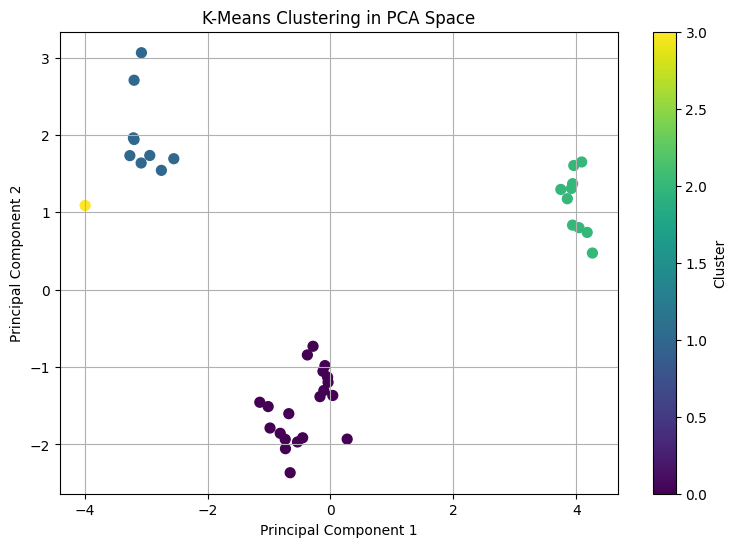

In [15]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering in PCA Space")
plt.colorbar(label="Cluster")
plt.grid(True)

plt.savefig(
    os.path.join(FIG, "kmeans_clusters.png"),
    dpi=300
)
plt.show()

K=2: Silhouette=0.4913, ARI=0.3158
K=3: Silhouette=0.5594, ARI=0.6977
K=4: Silhouette=0.5642, ARI=0.6656
K=5: Silhouette=0.4224, ARI=0.9669
K=6: Silhouette=0.3795, ARI=0.9051
K=7: Silhouette=0.3733, ARI=0.7670


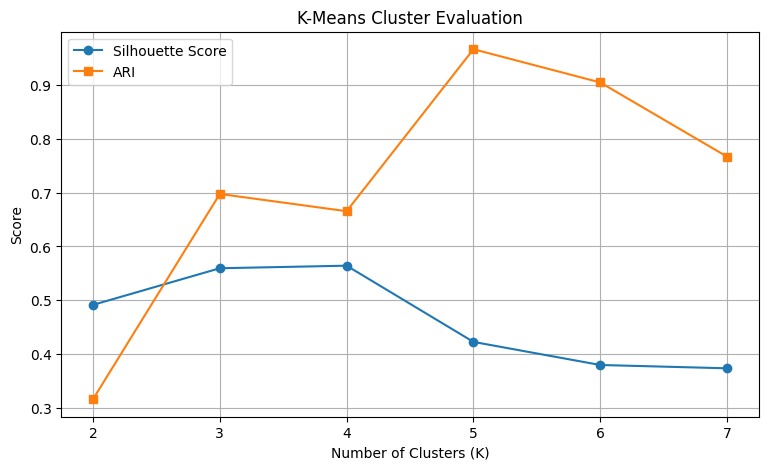

In [16]:
# Evaluate different numbers of clusters
k_values = range(2, 8)

silhouette_scores = []
ari_scores = []

for k in k_values:
    km = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=20
    )

    predicted = km.fit_predict(X_scaled)

    sil = silhouette_score(X_scaled, predicted)
    ari_value = adjusted_rand_score(y_features, predicted)

    silhouette_scores.append(sil)
    ari_scores.append(ari_value)

    print(
        f"K={k}: Silhouette={sil:.4f}, ARI={ari_value:.4f}"
    )

# Plot evaluation metrics
plt.figure(figsize=(9, 5))
plt.plot(k_values, silhouette_scores, marker="o", label="Silhouette Score")
plt.plot(k_values, ari_scores, marker="s", label="ARI")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Score")
plt.title("K-Means Cluster Evaluation")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(FIG, "kmeans_evaluation.png"),
    dpi=300
)
plt.show()

In [17]:
# K-Means on original 12-dimensional standardized features
km_12d = KMeans(n_clusters=4, random_state=SEED, n_init=20)
labels_12d = km_12d.fit_predict(X_scaled)

# K-Means on first two PCA components
X_2d = X_pca[:, :2]

km_2d = KMeans(n_clusters=4, random_state=SEED, n_init=20)
labels_2d = km_2d.fit_predict(X_2d)

print("12D Feature Space:")
print("ARI:", adjusted_rand_score(y_features, labels_12d))
print("NMI:", normalized_mutual_info_score(y_features, labels_12d))
print("Silhouette:", silhouette_score(X_scaled, labels_12d))

print("\n2D PCA Space:")
print("ARI:", adjusted_rand_score(y_features, labels_2d))
print("NMI:", normalized_mutual_info_score(y_features, labels_2d))
print("Silhouette:", silhouette_score(X_2d, labels_2d))

12D Feature Space:
ARI: 0.6655652584375737
NMI: 0.8293595724997522
Silhouette: 0.5642199102385558

2D PCA Space:
ARI: 1.0
NMI: 1.0
Silhouette: 0.7119623665575707


In [18]:
# Apply Gaussian Mixture Model
gmm = GaussianMixture(
    n_components=4,
    covariance_type="full",
    random_state=SEED,
    n_init=5
)

gmm_labels = gmm.fit_predict(X_scaled)

# Evaluate GMM
print("Gaussian Mixture Model Results")
print("--------------------------------")
print("ARI:", round(adjusted_rand_score(y_features, gmm_labels), 4))
print("NMI:", round(normalized_mutual_info_score(y_features, gmm_labels), 4))
print("Silhouette:", round(silhouette_score(X_scaled, gmm_labels), 4))
print("BIC:", round(gmm.bic(X_scaled), 4))
print("AIC:", round(gmm.aic(X_scaled), 4))

Gaussian Mixture Model Results
--------------------------------
ARI: 1.0
NMI: 1.0
Silhouette: 0.4081
BIC: -892.1167
AIC: -1505.1799


In [19]:
# Apply hierarchical Agglomerative clustering
agg = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

agg_labels = agg.fit_predict(X_scaled)

# Evaluate clustering
print("Agglomerative Clustering Results")
print("---------------------------------")
print("ARI:", round(adjusted_rand_score(y_features, agg_labels), 4))
print("NMI:", round(normalized_mutual_info_score(y_features, agg_labels), 4))
print("Silhouette:", round(silhouette_score(X_scaled, agg_labels), 4))

Agglomerative Clustering Results
---------------------------------
ARI: 0.6656
NMI: 0.8294
Silhouette: 0.5642


In [20]:
# Compare clustering algorithms
methods = {
    "K-Means": kmeans_labels,
    "GMM": gmm_labels,
    "Agglomerative": agg_labels
}

comparison = []

for name, predicted in methods.items():
    comparison.append({
        "Algorithm": name,
        "ARI": adjusted_rand_score(y_features, predicted),
        "NMI": normalized_mutual_info_score(y_features, predicted),
        "Silhouette": silhouette_score(X_scaled, predicted)
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4))

# Save comparison table
comparison_df.to_csv(
    os.path.join(TAB, "clustering_comparison.csv"),
    index=False
)

       Algorithm     ARI     NMI  Silhouette
0        K-Means  0.6656  0.8294      0.5642
1            GMM  1.0000  1.0000      0.4081
2  Agglomerative  0.6656  0.8294      0.5642


In [21]:
# Generate nonlinear two-moons dataset
X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=SEED
)

# Apply K-Means
km_moons = KMeans(
    n_clusters=2,
    random_state=SEED,
    n_init=20
)

km_moon_labels = km_moons.fit_predict(X_moons)

# Apply Spectral Clustering
spectral = SpectralClustering(
    n_clusters=2,
    affinity="nearest_neighbors",
    n_neighbors=15,
    assign_labels="kmeans",
    random_state=SEED
)

spectral_labels = spectral.fit_predict(X_moons)

# Evaluate both algorithms
print("K-Means ARI:",
      adjusted_rand_score(y_moons, km_moon_labels))

print("Spectral Clustering ARI:",
      adjusted_rand_score(y_moons, spectral_labels))

K-Means ARI: 0.24450207299571752
Spectral Clustering ARI: 0.9919999681285151


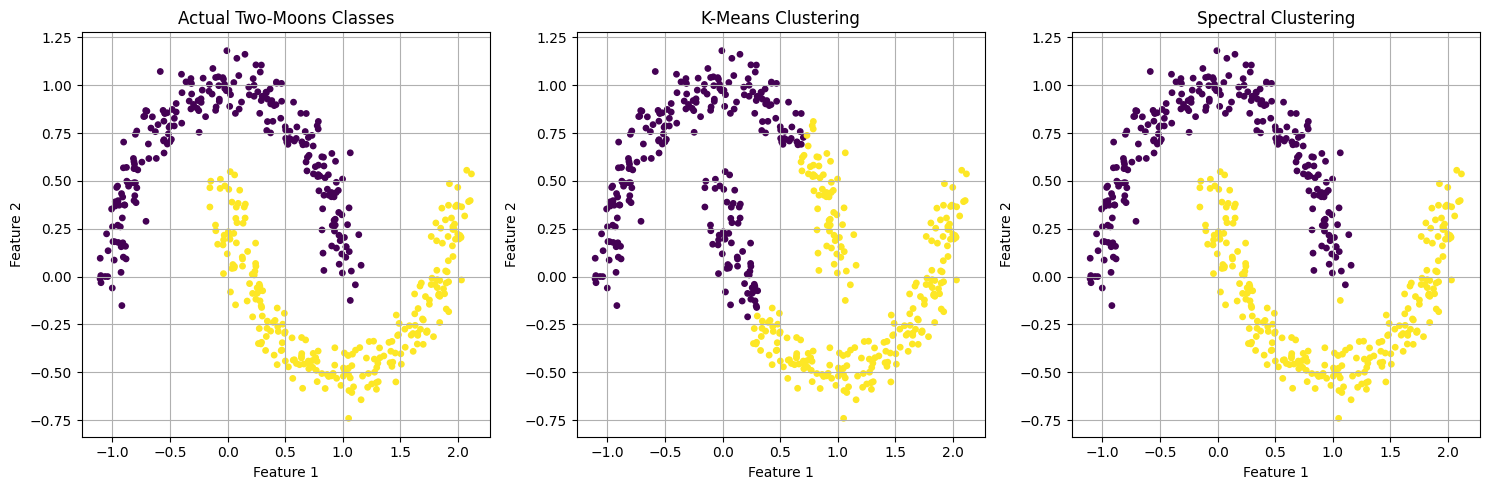

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].scatter(
    X_moons[:, 0], X_moons[:, 1],
    c=y_moons, cmap="viridis", s=15
)
axes[0].set_title("Actual Two-Moons Classes")

axes[1].scatter(
    X_moons[:, 0], X_moons[:, 1],
    c=km_moon_labels, cmap="viridis", s=15
)
axes[1].set_title("K-Means Clustering")

axes[2].scatter(
    X_moons[:, 0], X_moons[:, 1],
    c=spectral_labels, cmap="viridis", s=15
)
axes[2].set_title("Spectral Clustering")

for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(FIG, "spectral_vs_kmeans_moons.png"),
    dpi=300
)
plt.show()

SNR = 20 dB | ARI = 0.6656
SNR = 15 dB | ARI = 0.6625
SNR = 10 dB | ARI = 0.6061
SNR = 5 dB | ARI = 0.3902
SNR = 0 dB | ARI = 0.1477


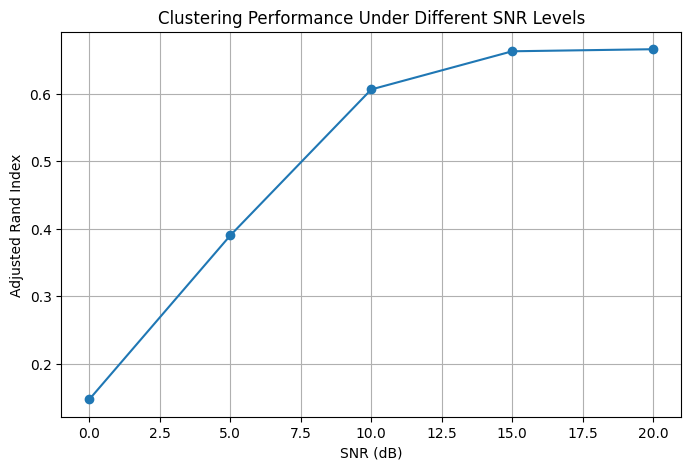

In [23]:
# Evaluate clustering performance at different SNR levels

snr_values = [20, 15, 10, 5, 0]
snr_ari = []

rng_snr = np.random.default_rng(SEED)

def generate_noisy_modulation(modulation, n, snr_db):
    if modulation == "BPSK":
        symbols = rng_snr.choice([-1, 1], n) + 0j

    elif modulation == "QPSK":
        phases = rng_snr.integers(0, 4, n) * np.pi/2 + np.pi/4
        symbols = np.exp(1j * phases)

    elif modulation == "8PSK":
        phases = rng_snr.integers(0, 8, n) * 2*np.pi/8
        symbols = np.exp(1j * phases)

    else:
        levels = np.array([-3, -1, 1, 3])
        symbols = (
            rng_snr.choice(levels, n)
            + 1j * rng_snr.choice(levels, n)
        ) / np.sqrt(10)

    signal_power = np.mean(np.abs(symbols)**2)
    noise_power = signal_power / (10**(snr_db/10))

    noise = np.sqrt(noise_power/2) * (
        rng_snr.normal(size=n)
        + 1j*rng_snr.normal(size=n)
    )

    return symbols + noise


for snr in snr_values:
    features = []
    true_labels = []

    for class_id, modulation in enumerate(modulations):
        noisy_signal = generate_noisy_modulation(
            modulation, 1000, snr
        )

        for start in range(0, 1000, group_size):
            group = noisy_signal[start:start+group_size]
            features.append(extract_features(group))
            true_labels.append(class_id)

    features = np.nan_to_num(
        np.array(features),
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    true_labels = np.array(true_labels)

    # Standardize each SNR dataset
    features_scaled = StandardScaler().fit_transform(features)

    # K-Means clustering
    km = KMeans(
        n_clusters=4,
        random_state=SEED,
        n_init=20
    )

    predicted = km.fit_predict(features_scaled)

    score = adjusted_rand_score(true_labels, predicted)
    snr_ari.append(score)

    print(f"SNR = {snr} dB | ARI = {score:.4f}")


# Plot SNR performance
plt.figure(figsize=(8, 5))
plt.plot(snr_values, snr_ari, marker="o")
plt.xlabel("SNR (dB)")
plt.ylabel("Adjusted Rand Index")
plt.title("Clustering Performance Under Different SNR Levels")
plt.grid(True)

plt.savefig(
    os.path.join(FIG, "snr_robustness.png"),
    dpi=300
)
plt.show()

In [24]:
# Create a summary of all major experiments

summary = {
    "Experiment": [
        "ICA Source Separation",
        "PCA Dimensionality Reduction",
        "K-Means Clustering",
        "Gaussian Mixture Model",
        "Agglomerative Clustering",
        "Spectral Clustering"
    ],
    "Result": [
        "FastICA applied successfully",
        f"{n_90} components for 90%, {n_95} for 95% variance",
        f"ARI = {adjusted_rand_score(y_features, kmeans_labels):.4f}",
        f"ARI = {adjusted_rand_score(y_features, gmm_labels):.4f}",
        f"ARI = {adjusted_rand_score(y_features, agg_labels):.4f}",
        f"Two-moons ARI = {adjusted_rand_score(y_moons, spectral_labels):.4f}"
    ]
}

summary_df = pd.DataFrame(summary)

# Save summary table
summary_df.to_csv(
    os.path.join(TAB, "experiment_summary.csv"),
    index=False
)

# Save SNR results
snr_df = pd.DataFrame({
    "SNR_dB": snr_values,
    "ARI": snr_ari
})

snr_df.to_csv(
    os.path.join(TAB, "snr_performance.csv"),
    index=False
)

# Save PCA variance results
pca_df = pd.DataFrame({
    "Principal_Component": range(1, len(cumulative_variance) + 1),
    "Explained_Variance": pca_full.explained_variance_ratio_,
    "Cumulative_Variance": cumulative_variance
})

pca_df.to_csv(
    os.path.join(TAB, "pca_variance.csv"),
    index=False
)

print("EXPERIMENT SUMMARY")
display(summary_df)

print("\nSNR PERFORMANCE")
display(snr_df)

print("\nPCA VARIANCE")
display(pca_df)

print("\nAll tables saved successfully!")

EXPERIMENT SUMMARY


,Experiment,Result
0,ICA Source Separation,FastICA applied successfully
1,PCA Dimensionality Reduction,"4 components for 90%, 5 for 95% variance"
2,K-Means Clustering,ARI = 0.6656
3,Gaussian Mixture Model,ARI = 1.0000
4,Agglomerative Clustering,ARI = 0.6656
5,Spectral Clustering,Two-moons ARI = 0.9920



SNR PERFORMANCE


,SNR_dB,ARI
0,20,0.665565
1,15,0.662513
2,10,0.606061
3,5,0.390156
4,0,0.147707



PCA VARIANCE


,Principal_Component,Explained_Variance,Cumulative_Variance
0,1,0.552973,0.552973
1,2,0.215591,0.768564
2,3,0.090504,0.859068
3,4,0.080383,0.939451
4,5,0.030544,0.969995
5,6,0.024244,0.994240
6,7,0.004378,0.998617
7,8,0.001088,0.999706
8,9,0.000162,0.999868
9,10,0.000106,0.999974



All tables saved successfully!


In [25]:
import os

print("FIGURES:")
for f in sorted(os.listdir(FIG)):
    print(f)

print("\nTABLES:")
for f in sorted(os.listdir(TAB)):
    print(f)

FIGURES:
gaussian_ica_test.png
ica_recovered_sources.png
ica_vs_pca.png
kmeans_clusters.png
kmeans_evaluation.png
modulation_constellations.png
pca_2d_projection.png
pca_explained_variance.png
pca_reconstruction_error.png
snr_robustness.png
spectral_vs_kmeans_moons.png

TABLES:
clustering_comparison.csv
experiment_summary.csv
pca_variance.csv
snr_performance.csv


In [26]:
readme_content = """
# ECM-402 AI for Signal Processing — Lab 7

## Title
Independent Component Analysis, Dimensionality Reduction
and Unsupervised Learning

## Objective
The objective of this laboratory assignment is to study
ICA, PCA and unsupervised clustering algorithms for
signal processing applications.

## Experiments

1. Independent Component Analysis (ICA)
2. Comparison of ICA and PCA
3. Gaussian source identifiability
4. PCA dimensionality reduction
5. K-Means clustering
6. Gaussian Mixture Model (GMM)
7. Agglomerative clustering
8. Spectral clustering
9. Clustering performance under different SNR levels

## Algorithms Used

- FastICA
- Principal Component Analysis (PCA)
- K-Means
- Gaussian Mixture Model
- Agglomerative Clustering
- Spectral Clustering

## Dataset
Synthetic independent source signals, digital modulation
signals (BPSK, QPSK, 8PSK and 16QAM), and two-moons
nonlinear clustering dataset.

## Results
- ICA successfully separates mixed source signals.
- PCA reduces dimensionality while retaining most variance.
- K-Means, GMM and Agglomerative clustering are evaluated.
- Spectral clustering handles nonlinear two-moons data.
- SNR experiments demonstrate the effect of noise on clustering.

## Installation

Install the required libraries:

    pip install -r requirements.txt

## Execution

Run the experiment notebook or execute the Python source
file after setting up the required dependencies.

## Reproducibility
Random seed: 0

## Folder Structure

    ecm402-lab7/
    ├── README.md
    ├── requirements.txt
    ├── report.pdf
    ├── src/
    └── results/
        ├── figures/
        └── tables/
"""

with open(os.path.join(ROOT, "README.md"), "w") as f:
    f.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [27]:
requirements = """
numpy
scipy
matplotlib
pandas
scikit-learn
"""

with open(os.path.join(ROOT, "requirements.txt"), "w") as f:
    f.write(requirements.strip())

print("requirements.txt created successfully!")

requirements.txt created successfully!
